# Compare Model 1 with other models (local)

After Progress Presentation 1 the panel asked for **more than LightGBM**: how do we know it is the right model?
This notebook answers that with one fair comparison. It is also task 6 of the charter: compare against
**rule-based, conventional ML, transfer learning and continual learning** approaches.

Every model gets **the same data, the same split by time and the same grades**:

| Family | Model | In one line |
|---|---|---|
| baseline | Rules | the hand-written policy the worker used before any model |
| baseline | Dwell >= 30 s | keep a screen if you stayed 30 seconds |
| conventional ML | **LightGBM (Model 1)** | many small decision trees, each fixing the last one's mistakes. Deployed today |
| conventional ML | Logistic regression | one weighted sum of the inputs: the simplest learner |
| conventional ML | Random forest | many independent trees that vote |
| conventional ML | Neural network (MLP) | two small layers of artificial neurons |
| transfer learning | MobileCLIP only + logistic regression | uses only *what the screen looks like*: MobileCLIP was pre-trained by Apple on millions of images, we train just a small layer on top |
| transfer learning | Features + MobileCLIP + logistic regression | the same, plus Model 1's inputs |
| continual learning | River adaptive random forest | learns one screen at a time while in use, and notices when your habits change |
| continual learning | LightGBM, retrained daily | what Model 2 (the learning loop) does: retrain from scratch every day |

It works on a **copy** of the live database and changes nothing, except the optional last step.

**Privacy:** the outputs show app names and counts, never titles or screenshots. Still, run an executed copy
outside the repo and **don't commit executed outputs**.

## 0. Settings
Change these if you want. Nothing else needs editing.

In [1]:
import os
import sys
from datetime import datetime
from pathlib import Path

TEST_FRACTION = 0.2      # newest 20% of labelled contexts are the test set (same as the learning loop)
KEEP_BUDGET = 0.3        # the storage budget: keep the top 30% of screens
RUN_ROLLING = True       # step 8: grade on several test periods (about 2 minutes)
N_FOLDS = 4
SAVE_RESULTS = True      # step 9: write the tables for the report (outside the repo)
RUN_LIVE_RETRAIN = False # step 10: retrain the live model now (writes to the live database)

DATA_DIR = Path(os.environ["LOCALAPPDATA"]) / "context-importance"   # where the installed app keeps its data
LIVE_DB = DATA_DIR / "context.db"
WORK_DIR = DATA_DIR / "model-comparison"
WORK_DIR.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("CONTEXT_IMPORTANCE_DATA", str(DATA_DIR))  # model versions go where the app reads them


def _find_worker_dir() -> Path:
    for base in (Path.cwd(), *Path.cwd().parents):
        for candidate in (base / "python-worker", base / "PCCILM" / "python-worker"):
            if (candidate / "offline" / "challengers.py").is_file():
                return candidate.resolve()
    raise FileNotFoundError("Open this notebook from inside the PCCILM folder.")


WORKER_DIR = _find_worker_dir()
sys.path.insert(0, str(WORKER_DIR))
import importlib.util

missing = [m for m in ("lightgbm", "sklearn", "river", "matplotlib") if importlib.util.find_spec(m) is None]
print("python        :", sys.executable)
if missing:
    print("MISSING       :", ", ".join(missing), "-> pick the kernel", WORKER_DIR / ".venv" / "Scripts" / "python.exe",
          "(top right: Select Kernel > Python Environments), or: pip install", " ".join(missing))
print("python-worker :", WORKER_DIR)
print("live database :", LIVE_DB, "(exists)" if LIVE_DB.is_file() else "(MISSING)")
print("results go to :", WORK_DIR)

python        : C:\Users\saime\source\repos\J26-IT-308\PCCILM\python-worker\.venv\Scripts\python.exe
python-worker : C:\Users\saime\source\repos\J26-IT-308\PCCILM\python-worker
live database : C:\Users\saime\AppData\Local\context-importance\context.db (exists)
results go to : C:\Users\saime\AppData\Local\context-importance\model-comparison


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from offline.challengers import (
    by_day, default_contenders, grade, keep_by_app, load_live_dataset, markdown_table, results_table, rolling_grade,
    snapshot_database, summarize_rolling, time_split,
)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 180)

## 1. Load a copy of the live database
The live file is copied first (it stays untouched, and capture can keep running). Two kinds of data are in it:
- **drc**: the DesktopResearchCollector history merged in (20 Sep to 19 Oct)
- **live**: what this app captured itself (from 19 Oct)

Only *labelled* contexts can be used for grading. A context gets its label 48 hours later: **did you come back to
it?** 1 = important, 0 = not. So the newest two days are never labelled yet.

In [3]:
snapshot = snapshot_database(LIVE_DB, WORK_DIR / "snapshot.db")
df = load_live_dataset(snapshot)
snapshot.unlink()

labelled = df[df["label"].notna()]
print(f"{len(df):,} contexts, {len(labelled):,} labelled, {labelled['label'].mean():.0%} of those important")
day = pd.to_datetime(df["ts"]).dt.tz_convert(None).dt.date
display(df.assign(day=day).groupby(["source"]).agg(contexts=("id", "size"), first=("day", "min"), last=("day", "max"),
                                                    labelled=("label", "count"), important=("label", "mean")))

39,400 contexts, 16,361 labelled, 56% of those important


,contexts,first,last,labelled,important
source,,,,,
drc,10379,2026-09-20,2026-10-19,10379,0.500915
live,29021,2026-10-19,2026-10-24,5982,0.652792


## 2. The revisit fix, visible
Model 1's strongest input is *"have you been on this page before?"* (`ctx_seen_before`). Until 24 Oct the worker
remembered only the last 200 snapshots, about 20 minutes, and forgot them on every restart. Now it remembers the
visits of the last 7 days, and the training data is recomputed the same way. The chart shows both versions per day.

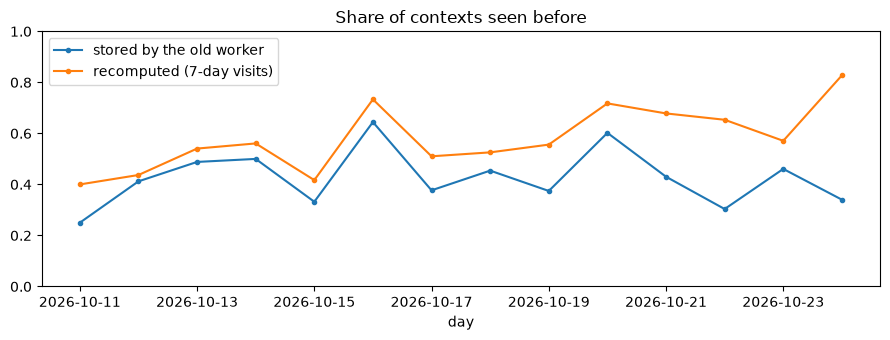

In [4]:
seen = pd.DataFrame({
    "day": day,
    "stored by the old worker": df["seen_before_stored"].astype(float),
    "recomputed (7-day visits)": [f.get("ctx_seen_before") for f in df["features"]],
}).groupby("day").mean()
seen.tail(14).plot(figsize=(9, 3.5), marker=".", title="Share of contexts seen before")
plt.ylim(0, 1); plt.tight_layout(); plt.show()

## 3. Split by time: older days train, newest days test
Testing on days that come *after* training is how the model is really used. The **embargo** drops training
contexts whose 48-hour label window reaches into the test days, so no answer from the test period leaks in.

In [5]:
train, test = time_split(df, test_fraction=TEST_FRACTION)
for name, part in (("train", train), ("test", test)):
    print(f"{name:5}: {len(part):6,} contexts  {part['ts'].min():%d %b %H:%M} -> {part['ts'].max():%d %b %H:%M}"
          f"   important {part['label'].mean():.0%}   sources {part['source'].value_counts().to_dict()}")
BASE_RATE = test["label"].mean()

train:  9,857 contexts  20 Sep 16:56 -> 18 Oct 15:39   important 50%   sources {'drc': 9857}
test :  3,272 contexts  20 Oct 15:42 -> 21 Oct 17:27   important 71%   sources {'live': 3272}


## 4. Train and grade every model
How to read the grades (higher is better for all of them):

- **avg_precision (AP)**: if you go down the model's list from most to least important, how clean is the list?
  A model that guesses at random scores the share of important contexts (printed as the *base rate*), not 0.
- **roc_auc**: the chance that a random important context is ranked above a random unimportant one. 0.5 = guessing.
- **recall_at_keep_30**: of the important contexts, how many survive when only the top 30% may be kept. This is the
  number that matters for storage.
- **train_seconds, ms_per_1000, size_kb**: cost. Remember it runs live on a laptop. For the two continual models,
  scoring time includes the learning they do while scoring.

None of these depend on a pass mark (threshold), so models that score on different scales are compared fairly.

In [6]:
graded = grade(default_contenders(), train, test, keep_budgets=(KEEP_BUDGET, 0.5))
results = results_table(graded)
print(f"\nbase rate (random guessing) AP = {BASE_RATE:.3f}")
recall_col = f"recall_at_keep_{int(KEEP_BUDGET * 100)}"
display(results.style.format(precision=3).background_gradient(subset=["avg_precision", "roc_auc", recall_col], cmap="Greens"))

Rules                                         AP 0.815  trained in    0.0s
Dwell >= 30 s                                 AP 0.713  trained in    0.0s
LightGBM (Model 1)                            AP 0.881  trained in    0.3s
Logistic regression                           AP 0.895  trained in    0.2s
Random forest                                 AP 0.878  trained in    1.3s
Neural network (MLP)                          AP 0.872  trained in    1.1s
MobileCLIP only + logistic regression         AP 0.872  trained in    0.1s
Features + MobileCLIP + logistic regression   AP 0.840  trained in    0.7s
River adaptive random forest                  AP 0.843  trained in   15.4s
LightGBM, retrained daily                     AP 0.881  trained in    0.0s

base rate (random guessing) AP = 0.711


,name,family,roc_auc,avg_precision,recall_at_keep_30,recall_at_keep_50,train_seconds,ms_per_1000,size_kb,note
0,Logistic regression,conventional ML,0.740,0.895,0.408,0.618,0.160,19.300,2.000,straight-line model
1,LightGBM (Model 1),conventional ML,0.712,0.881,0.402,0.589,0.300,13.700,178.500,deployed today
2,"LightGBM, retrained daily",continual learning,0.712,0.881,0.402,0.589,0.000,161.500,178.500,what Model 2 does
3,Random forest,conventional ML,0.690,0.878,0.405,0.603,1.260,42.100,31682.000,averaged trees (bagging)
4,MobileCLIP only + logistic regression,transfer learning,0.734,0.872,0.383,0.606,0.130,7.600,2.700,"what the screen looks like, nothing else"
5,Neural network (MLP),conventional ML,0.686,0.872,0.400,0.593,1.140,13.700,59.300,2 small hidden layers
6,River adaptive random forest,continual learning,0.702,0.843,0.386,0.602,15.410,191.600,28936.900,learns one context at a time
7,Features + MobileCLIP + logistic regression,transfer learning,0.637,0.840,0.370,0.540,0.680,21.700,16.000,"frozen pre-trained eyes, trained head"
8,Rules,baseline,0.617,0.815,0.384,0.518,0.000,1.800,0.900,"hand-written, served before any model"
9,Dwell >= 30 s,baseline,0.503,0.713,0.280,0.508,0.000,0.700,0.300,one fixed rule


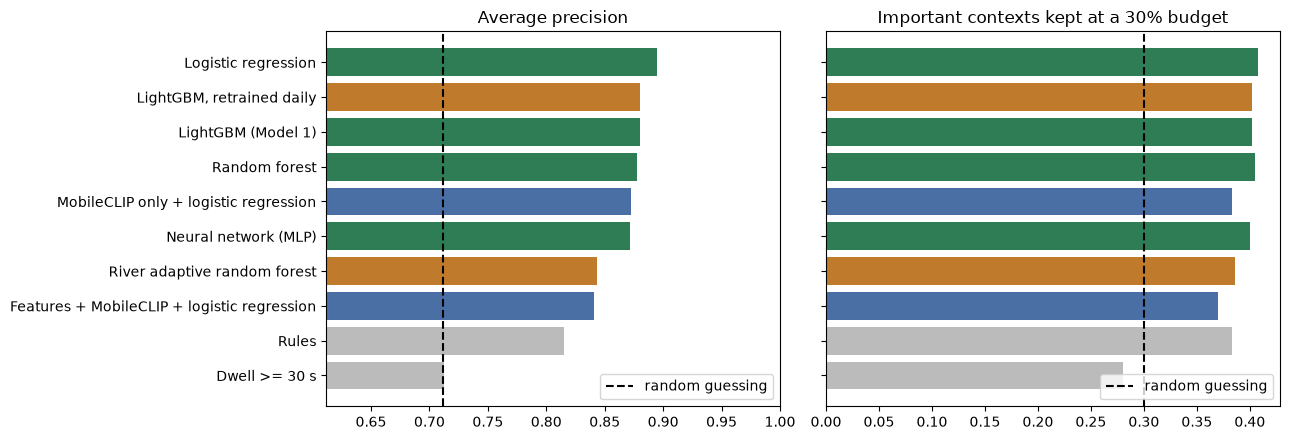

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
order = results.sort_values("avg_precision")
colors = order["family"].map({"baseline": "#bbb", "conventional ML": "#2f7d55", "transfer learning": "#4a6fa5",
                              "continual learning": "#c07a2c"})
axes[0].barh(order["name"], order["avg_precision"], color=colors)
axes[0].axvline(BASE_RATE, color="black", linestyle="--", label="random guessing")
axes[0].set_xlim(max(0, BASE_RATE - 0.1), 1); axes[0].set_title("Average precision"); axes[0].legend(loc="lower right")
axes[1].barh(order["name"], order[recall_col], color=colors)
axes[1].axvline(KEEP_BUDGET, color="black", linestyle="--", label="random guessing")  # random keeps 30% of everything
axes[1].set_title(f"Important contexts kept at a {KEEP_BUDGET:.0%} budget"); axes[1].legend(loc="lower right")
plt.tight_layout(); plt.show()

## 5. Which apps survive the budget?
Each model may keep only its top 30% of the test period. The table shows, per busy app, how much of it is
important by the labels (`important`) and how much each model keeps. A big gap between the two is where a model
is wrong.

In [8]:
apps = keep_by_app(test, graded, keep_budget=KEEP_BUDGET)
display(apps.style.format("{:.0%}", subset=apps.columns[1:]).format("{:,}", subset=["contexts"]))

,contexts,important,Rules,Dwell >= 30 s,LightGBM (Model 1),Logistic regression,Random forest,Neural network (MLP),MobileCLIP only + logistic regression,Features + MobileCLIP + logistic regression,River adaptive random forest,"LightGBM, retrained daily"
app,,,,,,,,,,,,
msedge,"1,190",68%,9%,22%,1%,0%,0%,4%,4%,1%,1%,1%
claude,596,100%,67%,69%,100%,100%,100%,100%,91%,100%,70%,100%
Code,408,76%,76%,23%,31%,40%,21%,16%,46%,31%,40%,31%
vlc,302,0%,0%,84%,0%,0%,0%,0%,1%,32%,0%,0%
AnyDesk (1),192,98%,64%,65%,49%,60%,78%,67%,27%,39%,74%,49%
explorer,183,74%,0%,0%,17%,11%,19%,25%,12%,3%,41%,17%
dbeaver,100,78%,0%,2%,39%,32%,38%,41%,4%,32%,41%,39%
CAPRLMComparison,91,69%,16%,19%,29%,9%,27%,16%,60%,4%,53%,29%
parsecd,50,82%,0%,24%,0%,0%,0%,0%,22%,0%,24%,0%


### Why browsers are thrown away: the data changed
The next cell compares the browser's training rows with its test rows. If the training rows all come from the DRC
history, where browser pages were rarely important, and the test rows from live capture, where they often are,
then the models learned an old habit. That is **data drift**: no choice of model fixes it, only training on
recent data does. The live labels arrive 48 hours late and the embargo removes two more days, so the first
live-only training rows appear about four days after live capture started. Re-run this notebook in a few days.

In [9]:
browser = ["msedge", "chrome", "firefox", "brave", "zen"]
rows = []
for name, part in (("train", train), ("test", test)):
    b = part[part["app"].str.lower().isin(browser)]
    for source, g in b.groupby("source"):
        rows.append({"split": name, "source": source, "browser contexts": len(g), "important": g["label"].mean()})
display(pd.DataFrame(rows).style.format({"important": "{:.0%}", "browser contexts": "{:,}"}))

,split,source,browser contexts,important
0,train,drc,"4,257",26%
1,test,live,"1,190",68%


## 6. Continual learning: does learning while in use help?
The two continual models keep learning **during** the test period, but fairly: a context's answer only arrives
48 hours after you saw it, like in real use. The chart shows the grade per test day. If the test period is only a
day or two (early on), they can't show their advantage yet: there is nothing new to learn from.

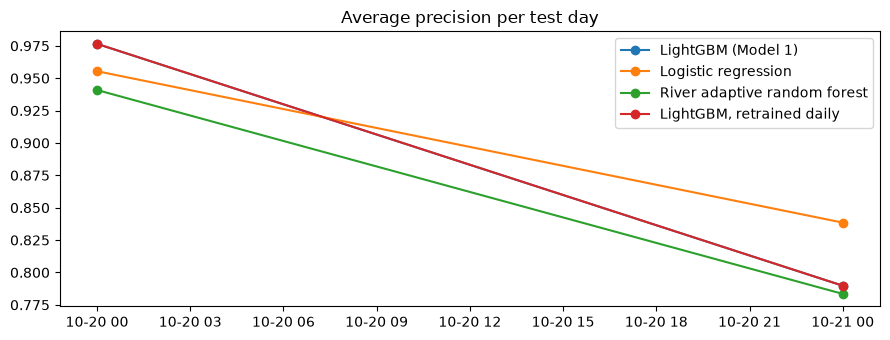

,LightGBM (Model 1),Logistic regression,River adaptive random forest,"LightGBM, retrained daily"
2026-10-20,0.977,0.955,0.941,0.977
2026-10-21,0.790,0.838,0.783,0.790


In [10]:
names = ["LightGBM (Model 1)", "LightGBM, retrained daily", "River adaptive random forest", "Logistic regression"]
daily = by_day(test, [g for g in graded if g.contender.name in names])
if len(daily) >= 2:
    daily.plot(figsize=(9, 3.5), marker="o", title="Average precision per test day")
    plt.tight_layout(); plt.show()
display(daily.round(3))

## 7. Robustness: several test periods
One test period can be lucky. Here the newest half of the labelled data is cut into consecutive periods, and every
model is trained on everything before each period and graded on it. `mean` is the average grade, `std` how much it
moves between periods, `folds_won` how often the model was best.

In [11]:
if RUN_ROLLING:
    rolling = rolling_grade(df, default_contenders, n_folds=N_FOLDS)
    rolling_summary = summarize_rolling(rolling)
    display(rolling_summary)

fold 0: train 6876, test 2045 (14 Oct to 18 Oct)
fold 1: train 9256, test 2045 (18 Oct to 20 Oct)
fold 2: train 9845, test 2045 (20 Oct to 21 Oct)
fold 3: train 10289, test 2045 (21 Oct to 21 Oct)


avg_precision        roc_auc        recall_at_keep_30        avg_precision
                                                     mean    std    mean    std              mean    std     folds_won
name                                                                                                                  
Logistic regression                                 0.837  0.051   0.745  0.060             0.434  0.055             1
LightGBM (Model 1)                                  0.830  0.059   0.737  0.084             0.443  0.045             1
LightGBM, retrained daily                           0.830  0.059   0.736  0.082             0.443  0.046             0
Random forest                                       0.828  0.055   0.723  0.100             0.437  0.053             2
Neural network (MLP)                                0.801  0.054   0.689  0.093             0.416  0.047             0
MobileCLIP only + logistic regression               0.792  0.054   0.705  0.021             0.403  0.022             0
River adaptive random forest                        0.785  0.051   0.709  0.064             0.418  0.043             0
Features + MobileCLIP + logistic regression         0.772  0.093   0.672  0.114             0.391  0.071             0
Rules                                               0.733  0.078   0.642  0.079             0.392  0.051             0
Dwell >= 30 s                                       0.626  0.104   0.528  0.078             0.314  0.058             0

## 8. Save the results for the report
Writes the tables as CSV and Markdown to `WORK_DIR` (outside the repo). Paste the Markdown table into the report.

In [12]:
if SAVE_RESULTS:
    out = WORK_DIR / datetime.now().strftime("%Y%m%d-%H%M")
    out.mkdir(parents=True, exist_ok=True)
    results.to_csv(out / "results.csv", index=False)
    apps.to_csv(out / "keep_by_app.csv")
    table = results[["name", "family", "avg_precision", "roc_auc", recall_col, "train_seconds", "size_kb"]].round(3)
    lines = [f"Test: {len(test):,} contexts, {test['ts'].min():%d %b} to {test['ts'].max():%d %b}; random-guess AP {BASE_RATE:.3f}.", "",
             markdown_table(table)]
    if RUN_ROLLING:
        rolling.to_csv(out / "rolling.csv", index=False)
        lines += ["", f"Rolling evaluation, {N_FOLDS} test periods:", "", markdown_table(rolling_summary, index=True)]
    (out / "results.md").write_text("\n".join(lines), encoding="utf-8")
    print("saved to", out)
    print("\n".join(lines))

saved to C:\Users\saime\AppData\Local\context-importance\model-comparison\20261024-2208
Test: 3,272 contexts, 20 Oct to 21 Oct; random-guess AP 0.711.

| name | family | avg_precision | roc_auc | recall_at_keep_30 | train_seconds | size_kb |
|---|---|---|---|---|---|---|
| Logistic regression | conventional ML | 0.895 | 0.740 | 0.408 | 0.160 | 2.000 |
| LightGBM (Model 1) | conventional ML | 0.881 | 0.712 | 0.402 | 0.300 | 178.500 |
| LightGBM, retrained daily | continual learning | 0.881 | 0.712 | 0.402 | 0.000 | 178.500 |
| Random forest | conventional ML | 0.878 | 0.690 | 0.405 | 1.260 | 31682.000 |
| MobileCLIP only + logistic regression | transfer learning | 0.872 | 0.734 | 0.383 | 0.130 | 2.700 |
| Neural network (MLP) | conventional ML | 0.872 | 0.686 | 0.400 | 1.140 | 59.300 |
| River adaptive random forest | continual learning | 0.843 | 0.702 | 0.386 | 15.410 | 28936.900 |
| Features + MobileCLIP + logistic regression | transfer learning | 0.840 | 0.637 | 0.370 | 0.680 | 16.00

## 9. (Optional) Retrain the live model
Runs the real learning loop once on the live database, with the corrected revisit features: label new contexts,
learn prototypes, retrain LightGBM, and **deploy only if it ranks better** than the model in use. A backup of the
live database is made first, in `backups`. Set `RUN_LIVE_RETRAIN = True` in step 0 to run it.

Afterwards click **Stop capture**, then **Start capture**, in the dashboard: the worker loads a new model only at
startup.

In [13]:
if RUN_LIVE_RETRAIN:
    from adaptation import scheduled_job

    backup = snapshot_database(LIVE_DB, DATA_DIR / "backups" / f"context.bak-{datetime.now():%Y%m%d-%H%M%S}.db")
    print("backup:", backup)
    scheduled_job.main([
        "--db", str(LIVE_DB), "--force", "--retrain-without-new-labels",
        "--versions-dir", str(DATA_DIR / "models" / "versions"),
        "--summary-log", str(DATA_DIR / "adaptation_runs.jsonl"),
    ])
    import json

    last = json.loads((DATA_DIR / "adaptation_runs.jsonl").read_text(encoding="utf-8").splitlines()[-1])
    print("decision:", last["decision"], "|", (last.get("stages") or {}).get("validation", {}).get("reason"))

## What to tell the panel
Fill these in from your own run (the numbers change as data grows):

1. **We compared ten models from four families** on the same time split, with the same threshold-free grades,
   and repeated it over several test periods (step 7).
2. **Learned models beat the rules**: name the AP of the best learner against the rules and random guessing.
3. **How close the learners are.** If LightGBM, logistic regression and random forest are within about 0.02 AP, the
   choice of learner matters less than the data. Then LightGBM is kept for its speed, small size and
   explainability (feature importances).
4. **Transfer learning:** what the frozen MobileCLIP vector adds on its own and with the features.
5. **Continual learning:** River against daily retraining. Daily retraining (Model 2) is simpler and as good or
   better, or else River wins when habits change. Say which, with step 6 and 7.
6. **The real problem we found is data drift** (step 5): browser pages were unimportant in the older DRC data and are
   important now. That is why the system needs continual learning at all, and it is the argument for Model 2.